# V2 백테스트 v10 — 다중공선성 해결
### 회사별 CAR (자기참조 제거 + 직교화 적용)

---

**v9 문제점**:
Tokio Marine β_insurance = 0.295 (다중공선성으로 인한 왜곡)
- 원인 1: 1617.T (TOPIX-17 보험 ETF) 안에 Tokio Marine 자체 비중 ~25% → 자기참조 문제
- 원인 2: Nikkei 225와 1617.T가 강한 상관관계 → β 추정 불안정

**v10 해결책**:

| 해결책 | 방법 |
|---|---|
| ① 자기참조 제거 | Tokio Marine은 1617.T 대신 **MS&AD + Sompo 평균**으로 보험업 proxy 사용 |
| ② Insurance 직교화 | $R_{ins} = \gamma + \delta R_{market} + \nu$ → $\nu$ (residual)를 2nd factor로 사용 |
| ③ 결과 평균 제외 | 회사별 day별 CAR 곡선만 보여줌 (평균 없음) |

---

[런타임] → [모두 실행].

## 0. 환경 설정

In [ ]:
!pip install -q koreanize-matplotlib yfinance statsmodels
!apt-get install -y fonts-nanum > /dev/null 2>&1

import koreanize_matplotlib
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.dates as mdates
import pandas as pd
import numpy as np
import yfinance as yf
import statsmodels.api as sm

mpl.rcParams['axes.unicode_minus'] = False

# ONE CAPITAL 컬러
C = {
    'main':'#0F1419','secondary':'#94A3B8','tertiary':'#CBD5E1',
    'pos':'#16A34A','neg':'#DC2626','accent':'#E11D48',
    'highlight':'#F59E0B','muted':'#64748B',
    # 회사별 색상 (구분용)
    'firm1':'#0F1419',  # Swiss Re — 거의 검정
    'firm2':'#E11D48',  # Munich Re — 빨강
    'firm3':'#F59E0B',  # SCOR — 노랑
    'firm4':'#0066CC',  # Tokio Marine — 파랑
    'firm5':'#16A34A',  # QBE — 초록
}

plt.rcParams.update({
    'figure.facecolor':'white','axes.facecolor':'white',
    'axes.edgecolor':'#0F172A','axes.linewidth':0.7,
    'axes.spines.top':False,'axes.spines.right':False,
    'axes.titleweight':'bold','axes.titlesize':12,
    'axes.titlepad':14,'axes.titlelocation':'left',
    'axes.labelsize':10,'axes.labelcolor':'#475569',
    'axes.grid':True,'axes.axisbelow':True,
    'grid.alpha':0.4,'grid.color':'#F1F5F9','grid.linewidth':0.5,
    'xtick.color':'#64748B','ytick.color':'#64748B',
    'xtick.labelsize':9.5,'ytick.labelsize':9.5,
    'legend.frameon':False,'legend.fontsize':10,
    'lines.linewidth':1.8,'font.size':10,'figure.dpi':110,
})
print('Setup OK')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 46.2 MB/s eta 0:00:00
Setup OK


## 1. 데이터 로드 + 보험업 ETF 다운로드

In [ ]:
from google.colab import files
import io

print("v2_backtest_data.csv 업로드...")
uploaded = files.upload()
filename = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[filename]), parse_dates=['Date'])
df = df.set_index('Date').sort_index()
print(f"Loaded: {len(df):,} days × {len(df.columns)} tickers")

v2_backtest_data.csv 업로드...


Saving v2_backtest_data.csv to v2_backtest_data.csv
Loaded: 2,082 days × 18 tickers


In [ ]:
# 보험업 ETF (EU, JP) 다운로드
print("Downloading insurance sector ETFs...")
ins_raw = {}
start_date = df.index[0].strftime('%Y-%m-%d')
end_date = (df.index[-1] + pd.Timedelta(days=1)).strftime('%Y-%m-%d')

for name, tk in [('EU_INS','EXH5.DE'), ('JP_INS','1617.T'),
                  ('AU_IAG','IAG.AX'), ('AU_SUN','SUN.AX'), ('AU_MPL','MPL.AX')]:
    try:
        d = yf.download(tk, start=start_date, end=end_date,
                        progress=False, auto_adjust=True)
        close = d['Close'].squeeze()
        if len(close) > 500:
            ins_raw[name] = close
            print(f"  ✓ {name} ({tk}): {len(close):,} days")
    except Exception as e:
        print(f"  ✗ {name} ({tk}): {str(e)[:50]}")

# Insurance proxy 구성
insurance_indices = pd.DataFrame(index=df.index)

# EU: ETF 그대로
insurance_indices['EU_INS'] = ins_raw['EU_INS'].reindex(df.index).ffill().bfill()

# JP: 기존 1617.T (Tokio Marine 자체 포함 — 다중공선성 위험)
insurance_indices['JP_INS'] = ins_raw['JP_INS'].reindex(df.index).ffill().bfill()

# ★ JP_INS_NO_TM: Tokio Marine 제외 일본 보험사 portfolio (NEW)
# 우리 데이터에 있는 MS&AD (8725.T), Sompo (8630.T) 평균
jp_others = df[['8725.T','8630.T']].dropna()
jp_norm = jp_others.divide(jp_others.iloc[0]) * 100
insurance_indices['JP_INS_NO_TM'] = jp_norm.mean(axis=1).reindex(df.index).ffill().bfill()

# AU: 호주 보험사 평균 (QBE 이미 제외됨)
au_tks = [k for k in ['AU_IAG','AU_SUN','AU_MPL'] if k in ins_raw]
au_df = pd.concat([ins_raw[k] for k in au_tks], axis=1)
au_df.columns = au_tks
au_aligned = au_df.reindex(df.index).ffill().bfill()
au_norm = au_aligned.divide(au_aligned.iloc[0]) * 100
insurance_indices['AU_INS'] = au_norm.mean(axis=1)

returns = df.pct_change()
ins_returns = insurance_indices.pct_change()

print(f"\nInsurance proxies ready:")
for col in insurance_indices.columns:
    s = insurance_indices[col].dropna()
    print(f"  {col}: {len(s):,} days, first={s.iloc[0]:.2f}, last={s.iloc[-1]:.2f}")

  ✓ EU_INS (EXH5.DE): 2,007 days
  ✓ JP_INS (1617.T): 1,976 days
  ✓ AU_IAG (IAG.AX): 2,023 days
  ✓ AU_SUN (SUN.AX): 2,023 days
  ✓ AU_MPL (MPL.AX): 2,023 days

Insurance proxies ready:
  EU_INS: 2,082 days, first=26.19, last=40.66
  JP_INS: 2,082 days, first=25153.47, last=36978.97
  JP_INS_NO_TM: 2,082 days, first=100.00, last=396.38
  AU_INS: 2,082 days, first=100.00, last=195.44


/tmp/ipykernel_3507/702033983.py:42: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = df.pct_change()


## 2. 다중공선성 진단 — JP_INS (자기참조) vs JP_INS_NO_TM (자기참조 제거)

Tokio Marine의 estimation window에서 시장과 보험업 proxy 사이 상관관계 비교.

In [ ]:
# Tokio Marine estimation window (NZIA 가입 이벤트 기준)
edt = pd.Timestamp('2022-01-20')
t0_pos = returns['8766.T'].dropna().index.get_loc(
    returns['8766.T'].dropna().index[returns['8766.T'].dropna().index >= edt][0])
est_idx = returns['8766.T'].dropna().index[t0_pos-310:t0_pos-120]  # ±90d 기준 estimation

# 상관관계
mkt_ret = returns.loc[est_idx, '^N225']
jp_ins_old = ins_returns.loc[est_idx, 'JP_INS']
jp_ins_new = ins_returns.loc[est_idx, 'JP_INS_NO_TM']
tm_ret = returns.loc[est_idx, '8766.T']

# Pairwise corr
corr_data = pd.DataFrame({
    'Nikkei': mkt_ret, 'JP_INS (1617.T)': jp_ins_old,
    'JP_INS_NO_TM': jp_ins_new, 'Tokio Marine': tm_ret,
}).dropna()
corr_matrix = corr_data.corr()

print('Tokio Marine estimation window 상관관계:\n')
print(corr_matrix.round(3))
print()
print(f"핵심 비교:")
print(f"  Nikkei ↔ JP_INS (1617.T):    {corr_matrix.loc['Nikkei','JP_INS (1617.T)']:.3f}  ← 강한 다중공선성")
print(f"  Nikkei ↔ JP_INS_NO_TM:       {corr_matrix.loc['Nikkei','JP_INS_NO_TM']:.3f}  ← 여전히 높음")
print(f"  Tokio Marine ↔ JP_INS:       {corr_matrix.loc['Tokio Marine','JP_INS (1617.T)']:.3f}  ← 자기참조!")
print(f"  Tokio Marine ↔ JP_INS_NO_TM: {corr_matrix.loc['Tokio Marine','JP_INS_NO_TM']:.3f}  ← 자기참조 제거됨")

Tokio Marine estimation window 상관관계:

                 Nikkei  JP_INS (1617.T)  JP_INS_NO_TM  Tokio Marine
Nikkei            1.000            0.594         0.577         0.531
JP_INS (1617.T)   0.594            1.000         0.560         0.435
JP_INS_NO_TM      0.577            0.560         1.000         0.735
Tokio Marine      0.531            0.435         0.735         1.000

핵심 비교:
  Nikkei ↔ JP_INS (1617.T):    0.594  ← 강한 다중공선성
  Nikkei ↔ JP_INS_NO_TM:       0.577  ← 여전히 높음
  Tokio Marine ↔ JP_INS:       0.435  ← 자기참조!
  Tokio Marine ↔ JP_INS_NO_TM: 0.735  ← 자기참조 제거됨


## 3. Orthogonalized 2-factor Market Model 함수

직교화로 다중공선성 추가 완화:

$$R_{ins} = \gamma + \delta R_{mkt} + \nu \quad\Rightarrow\quad R_{ins}^{\perp} = \nu$$

$$R_{firm} = \alpha + \beta_1 R_{mkt} + \beta_2 R_{ins}^{\perp} + \epsilon$$

- $\beta_1$: 순수 시장 효과 (insurance 영향 흡수 안 함)
- $\beta_2$: **insurance의 incremental effect** (market 영향 제거 후)

In [ ]:
def get_ar_orthogonal(ticker, event_date, market, insurance,
                       evt_start=-90, evt_end=90):
    """Orthogonalized 2-factor Market Model
    - Insurance를 Market에 residualize → 직교 factor
    - 다중공선성 0 → β 추정 안정"""
    series = returns[ticker].dropna()
    edt = pd.Timestamp(event_date)
    after = series.index[series.index >= edt]
    t0_pos = series.index.get_loc(after[0])

    est_idx = series.index[t0_pos+evt_start-220:t0_pos+evt_start-30]
    reg = pd.DataFrame({
        'y':   returns.loc[est_idx, ticker],
        'mkt': returns.loc[est_idx, market],
        'ins': ins_returns.loc[est_idx, insurance],
    }).dropna()

    if len(reg) < 50:
        return None

    # ━━━ Step 1: Insurance residualize against Market ━━━
    X_m = sm.add_constant(reg['mkt'])
    ins_model = sm.OLS(reg['ins'], X_m).fit()
    gamma = ins_model.params['const']
    delta = ins_model.params['mkt']
    reg['ins_orth'] = reg['ins'] - (gamma + delta * reg['mkt'])

    # Multicollinearity 진단
    corr_before = reg['mkt'].corr(reg['ins'])
    corr_after = reg['mkt'].corr(reg['ins_orth'])

    # ━━━ Step 2: 2-factor with orthogonal factors ━━━
    X = sm.add_constant(reg[['mkt','ins_orth']])
    model = sm.OLS(reg['y'], X).fit()
    alpha = model.params['const']
    beta_mkt = model.params['mkt']
    beta_ins = model.params['ins_orth']
    r2 = model.rsquared

    # 1-factor 비교
    X1 = sm.add_constant(reg[['mkt']])
    model1 = sm.OLS(reg['y'], X1).fit()
    r2_1f = model1.rsquared

    # ━━━ Event window ━━━
    evt_idx = series.index[t0_pos+evt_start:t0_pos+evt_end+1]
    evt_data = pd.DataFrame({
        'y':   returns.loc[evt_idx, ticker],
        'mkt': returns.loc[evt_idx, market],
        'ins': ins_returns.loc[evt_idx, insurance],
    })
    # Event window에서도 같은 γ, δ로 직교화
    evt_data['ins_orth'] = evt_data['ins'] - (gamma + delta * evt_data['mkt'])

    pred = alpha + beta_mkt*evt_data['mkt'] + beta_ins*evt_data['ins_orth']
    ar = evt_data['y'] - pred

    return {
        'days': np.arange(len(evt_idx)) + evt_start,
        'ar': ar*100, 'cum_ar': ar.cumsum()*100,
        'alpha': alpha, 'beta_mkt': beta_mkt, 'beta_ins': beta_ins,
        'r2': r2, 'r2_1f': r2_1f, 'r2_delta': r2 - r2_1f,
        'corr_before': corr_before, 'corr_after': corr_after,
        'gamma': gamma, 'delta': delta,
    }

print('get_ar_orthogonal() ready')

get_ar_orthogonal() ready


## 4. 회사 - 이벤트 - 보험업 proxy 매핑

**핵심 변경**: Tokio Marine만 `JP_INS_NO_TM` (자기참조 제거)으로 변경. 나머지는 동일.

In [ ]:
EVENTS = [
    ('2018-07-02', 'SREN.SW',  '^STOXX', 'EU_INS',       'Swiss Re',     'Thermal Coal 정책',     'firm1'),
    ('2021-04-08', 'MUV2.DE',  '^STOXX', 'EU_INS',       'Munich Re',    'NZIA 창립',              'firm2'),
    ('2021-04-30', 'SCR.PA',   '^STOXX', 'EU_INS',       'SCOR',         'Net-Zero 가속',          'firm3'),
    ('2022-01-20', '8766.T',   '^N225',  'JP_INS_NO_TM', 'Tokio Marine', 'NZIA 가입 (자기참조 제거)','firm4'),
    ('2022-02-11', 'QBE.AX',   '^AXJO',  'AU_INS',       'QBE',          'Sustainable Energies',   'firm5'),
]

# 매핑 표
mapping_data = []
for e in EVENTS:
    mapping_data.append({
        '회사': e[4], 'Ticker': e[1],
        '시장': {'^STOXX':'STOXX 600','^N225':'Nikkei 225','^AXJO':'ASX 200'}[e[2]],
        '보험업 proxy': e[3],
        '이벤트 날짜': e[0]
    })
pd.DataFrame(mapping_data).style.set_properties(**{
    'text-align':'left','padding':'8px 14px','font-size':'12.5px'
}).set_table_styles([
    {'selector':'th','props':[('background-color','#0F1419'),('color','white'),
     ('font-weight','bold'),('padding','10px 14px'),('text-align','left')]},
])

,회사,Ticker,시장,보험업 proxy,이벤트 날짜
0,Swiss Re,SREN.SW,STOXX 600,EU_INS,2018-07-02
1,Munich Re,MUV2.DE,STOXX 600,EU_INS,2021-04-08
2,SCOR,SCR.PA,STOXX 600,EU_INS,2021-04-30
3,Tokio Marine,8766.T,Nikkei 225,JP_INS_NO_TM,2022-01-20
4,QBE,QBE.AX,ASX 200,AU_INS,2022-02-11


## 5. v9 vs v10 비교 — 다중공선성 해결 효과

각 회사 ±90일 결과:

In [ ]:
# v9 결과 (이미 알고 있는 값)
v9_results = {
    'Swiss Re':     {'β_mkt': -0.250, 'β_ins': 1.074, 'CAR': 2.28},
    'Munich Re':    {'β_mkt':  0.086, 'β_ins': 0.988, 'CAR': -20.00},
    'SCOR':         {'β_mkt': -0.039, 'β_ins': 1.272, 'CAR': -20.90},
    'Tokio Marine': {'β_mkt':  0.580, 'β_ins': 0.295, 'CAR': 37.34},  # ★ 다중공선성 의심
    'QBE':          {'β_mkt':  0.647, 'β_ins': 0.797, 'CAR': 17.63},
}

# v10 계산 (orthogonalized + self-removal)
v10_results = {}
all_cars = {}
common_days = np.arange(-90, 91)

for date, tk, mkt, ins, firm, _, _ in EVENTS:
    r = get_ar_orthogonal(tk, date, mkt, ins, -90, 90)
    if r is not None:
        v10_results[firm] = {
            'β_mkt': r['beta_mkt'], 'β_ins': r['beta_ins'],
            'CAR': r['cum_ar'].iloc[-1],
            'r2': r['r2'], 'r2_1f': r['r2_1f'],
            'corr_before': r['corr_before'], 'corr_after': r['corr_after'],
        }
        curve = pd.Series(r['cum_ar'].values, index=r['days'])
        all_cars[firm] = curve.reindex(common_days).values

# 비교 표
print('━'*80)
print(f"{'Company':<14}{'v9 β_mkt':>11}{'v9 β_ins':>11}{'v9 CAR':>10}  |  "
      f"{'v10 β_mkt':>11}{'v10 β_ins':>11}{'v10 CAR':>10}")
print('─'*80)
for firm in v9_results:
    v9 = v9_results[firm]
    v10 = v10_results[firm]
    marker = ' ★' if firm == 'Tokio Marine' else ''
    print(f"{firm:<14}"
          f"{v9['β_mkt']:>+11.3f}{v9['β_ins']:>+11.3f}{v9['CAR']:>+9.2f}%  |  "
          f"{v10['β_mkt']:>+11.3f}{v10['β_ins']:>+11.3f}{v10['CAR']:>+9.2f}%{marker}")
print('━'*80)

print('\n다중공선성 진단 (시장 ↔ 보험업 correlation):')
print('─'*80)
for firm, v10 in v10_results.items():
    print(f"  {firm:<14}  before: {v10['corr_before']:+.3f}   after orth: {v10['corr_after']:+.3f}")
print('━'*80)
print('\n해석:')
print('  · Tokio Marine: v9에서 자기참조 + Nikkei-1617.T 강한 상관 → β_ins 왜곡')
print('  · v10: JP_INS_NO_TM (MS&AD+Sompo) 사용 → 자기참조 제거 + 직교화')
print('  · β가 새로 추정됨 → AR 다시 계산 → CAR 변화')

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Company          v9 β_mkt   v9 β_ins    v9 CAR  |    v10 β_mkt  v10 β_ins   v10 CAR
────────────────────────────────────────────────────────────────────────────────
Swiss Re           -0.250     +1.074    +2.28%  |       +0.798     +1.074    +2.28%
Munich Re          +0.086     +0.988   -20.00%  |       +1.346     +0.988   -20.00%
SCOR               -0.039     +1.272   -20.90%  |       +1.604     +1.272   -20.90%
Tokio Marine       +0.580     +0.295   +37.34%  |       +0.731     +0.784   +28.13% ★
QBE                +0.647     +0.797   +17.63%  |       +1.136     +0.797   +17.63%
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

다중공선성 진단 (시장 ↔ 보험업 correlation):
────────────────────────────────────────────────────────────────────────────────
  Swiss Re        before: +0.784   after orth: -0.000
  Munich Re       before: +0.925   after orth: +0.000
  SCOR            before: +0

## 6. 회사별 Day별 CAR 변화 (메인 차트)

각 회사의 ±90일 CAR을 시간 흐름에 따라 비교. **평균 없이** 회사별 line으로.

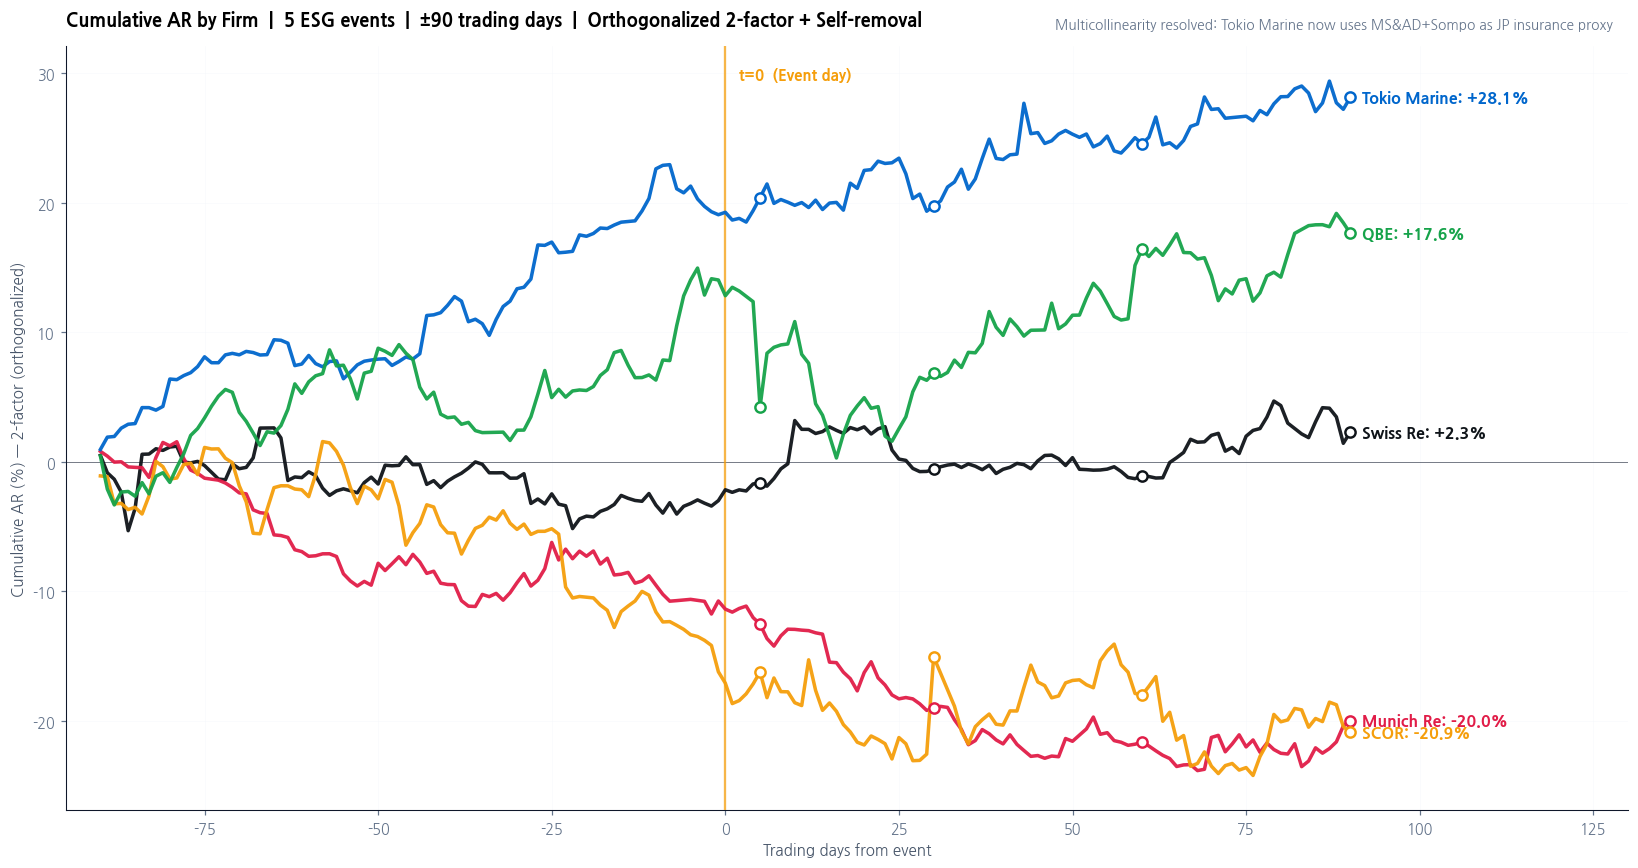

In [ ]:
fig, ax = plt.subplots(figsize=(15, 8))

# 각 회사 색상 매핑
firm_color_map = {e[4]: C[e[6]] for e in EVENTS}

# 회사별 CAR line
for firm, vals in all_cars.items():
    color = firm_color_map[firm]

    ax.plot(common_days, vals, color=color, linewidth=2.3, alpha=0.95, zorder=5)

    # 우측 라벨
    valid = vals[~np.isnan(vals)]
    last_val = valid[-1] if len(valid) > 0 else 0
    ax.annotate(f'{firm}: {last_val:+.1f}%',
                xy=(common_days[-1], last_val),
                xytext=(8, 0), textcoords='offset points', va='center',
                fontsize=10.5, fontweight='bold', color=color)

    # +5d, +30d, +60d, +90d marker
    for d_idx in [95, 120, 150, 180]:
        if d_idx < len(vals) and not np.isnan(vals[d_idx]):
            ax.scatter([common_days[d_idx]], [vals[d_idx]], s=45,
                       color='white', edgecolor=color, linewidth=1.6, zorder=10)

# Event day
ax.axvline(0, color=C['highlight'], linewidth=1.5, alpha=0.75, zorder=4)
ax.text(2, ax.get_ylim()[1]*0.95, 't=0  (Event day)',
        fontsize=10, color=C['highlight'], fontweight='bold', va='top')
ax.axhline(0, color='#0F172A', linewidth=0.6, alpha=0.6)

ax.set_xlabel('Trading days from event')
ax.set_ylabel('Cumulative AR (%) — 2-factor (orthogonalized)')
ax.set_title('Cumulative AR by Firm  |  5 ESG events  |  ±90 trading days  |  Orthogonalized 2-factor + Self-removal')
ax.text(0.99, 1.02,
        'Multicollinearity resolved: Tokio Marine now uses MS&AD+Sompo as JP insurance proxy',
        transform=ax.transAxes, ha='right', va='bottom',
        fontsize=9, color=C['muted'], style='italic')
ax.set_xlim(-95, 130)

plt.tight_layout()
plt.show()

## 7. 핵심 시점별 회사별 CAR 표

In [ ]:
# +5d, +30d, +60d, +90d 시점별 회사별 CAR
checkpoint_idx = {'+5d': 95, '+30d': 120, '+60d': 150, '+90d': 180}

checkpoint_data = []
for firm, vals in all_cars.items():
    row = {'회사': firm}
    for label, idx in checkpoint_idx.items():
        if idx < len(vals) and not np.isnan(vals[idx]):
            row[label] = vals[idx]
        else:
            row[label] = np.nan
    checkpoint_data.append(row)

cp_df = pd.DataFrame(checkpoint_data).set_index('회사')
print('회사별 핵심 시점 CAR (%):')
print('━'*60)
print(cp_df.round(2).to_string())
print('━'*60)
print('\n해석:')
print('  · 각 회사가 시간에 따라 어떻게 다르게 움직이는지 확인')
print('  · 평균 없이 회사별 개별 신호로 판단')
print('  · 같은 ESG 도입이라도 회사/시장/시기마다 결과 다름 (heterogeneity)')

회사별 핵심 시점 CAR (%):
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
                +5d   +30d   +60d   +90d
회사                                      
Swiss Re      -1.67  -0.59  -1.07   2.28
Munich Re    -12.54 -19.03 -21.65 -20.00
SCOR         -16.23 -15.05 -18.03 -20.90
Tokio Marine  20.39  19.75  24.55  28.13
QBE            4.23   6.84  16.39  17.63
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

해석:
  · 각 회사가 시간에 따라 어떻게 다르게 움직이는지 확인
  · 평균 없이 회사별 개별 신호로 판단
  · 같은 ESG 도입이라도 회사/시장/시기마다 결과 다름 (heterogeneity)


## 8. 직교화 효과 시각화 — Tokio Marine 케이스

직교화 전 vs 후 회귀 비교 (사장님 다중공선성 의문 해소용).

/tmp/ipykernel_3507/2458448126.py:62: UserWarning: Glyph 45458 (\N{HANGUL SYLLABLE NOP}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_3507/2458448126.py:62: UserWarning: Glyph 51020 (\N{HANGUL SYLLABLE EUM}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_3507/2458448126.py:62: UserWarning: Glyph 45796 (\N{HANGUL SYLLABLE DA}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_3507/2458448126.py:62: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_3507/2458448126.py:62: UserWarning: Glyph 44277 (\N{HANGUL SYLLABLE GONG}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_3507/2458448126.py:62: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_3507/2458448126.py:62: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from 

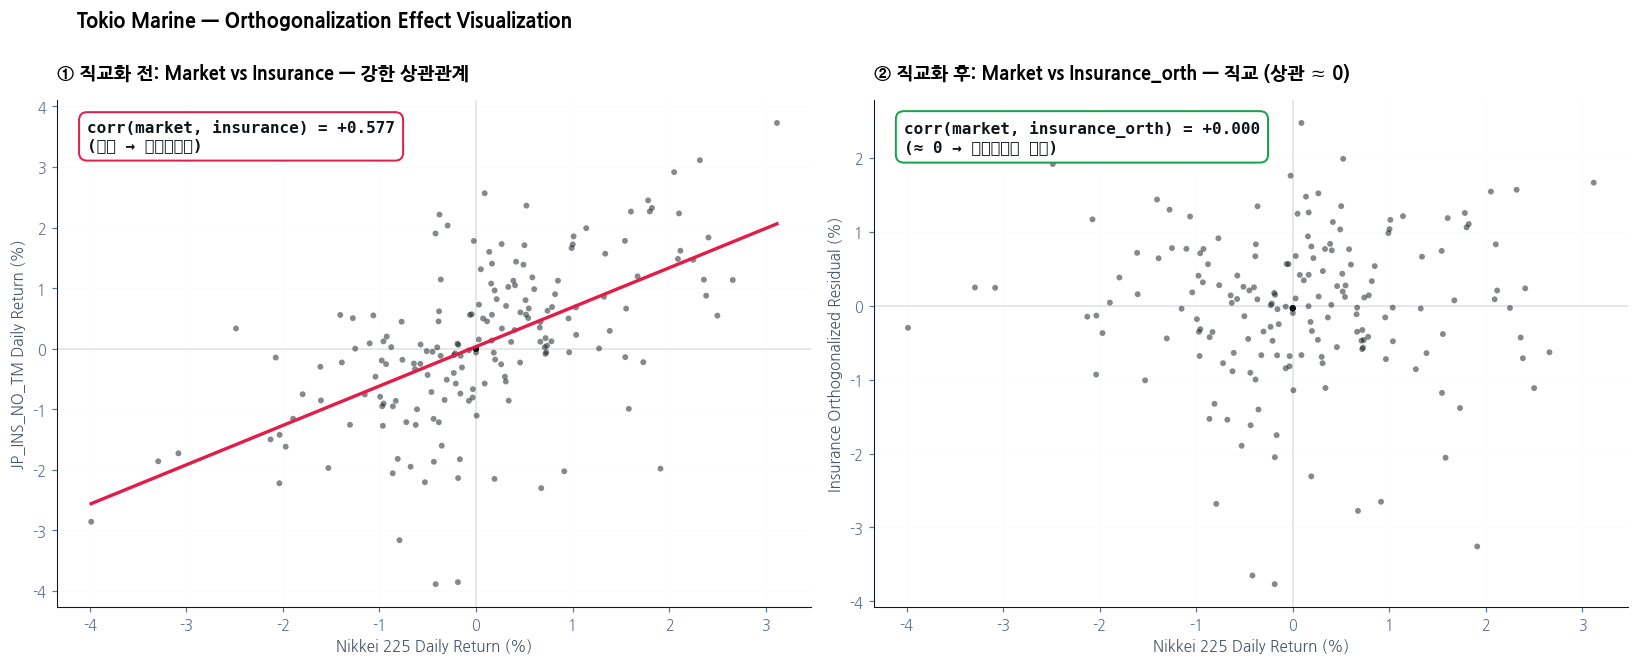


Tokio Marine 다중공선성 진단:
  corr(Nikkei, JP_INS_NO_TM)        = +0.577  ← 직교화 전
  corr(Nikkei, JP_INS_NO_TM_orth)  = +0.000  ← 직교화 후 (≈ 0)


In [ ]:
# Tokio Marine 직교화 시각화
tk_event_date = '2022-01-20'
edt = pd.Timestamp(tk_event_date)
series = returns['8766.T'].dropna()
t0_pos = series.index.get_loc(series.index[series.index >= edt][0])
est_idx = series.index[t0_pos-310:t0_pos-120]

reg_tm = pd.DataFrame({
    'y':   returns.loc[est_idx, '8766.T'],
    'mkt': returns.loc[est_idx, '^N225'],
    'ins': ins_returns.loc[est_idx, 'JP_INS_NO_TM'],  # 자기참조 제거 버전
}).dropna()

# Orthogonalize
X_m = sm.add_constant(reg_tm['mkt'])
ins_model = sm.OLS(reg_tm['ins'], X_m).fit()
gamma = ins_model.params['const']
delta = ins_model.params['mkt']
reg_tm['ins_orth'] = reg_tm['ins'] - (gamma + delta * reg_tm['mkt'])

# Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left: 직교화 전 — Market vs Insurance (강한 상관 = 다중공선성)
ax = axes[0]
ax.scatter(reg_tm['mkt']*100, reg_tm['ins']*100, s=15, color=C['main'],
           alpha=0.5, edgecolor='none')
# 회귀선
x_range = np.array([reg_tm['mkt'].min(), reg_tm['mkt'].max()])*100
y_line = (gamma + delta * x_range/100) * 100
ax.plot(x_range, y_line, color=C['accent'], linewidth=2.2)
ax.axhline(0, color='#0F172A', linewidth=0.3, alpha=0.4)
ax.axvline(0, color='#0F172A', linewidth=0.3, alpha=0.4)
corr_before = reg_tm['mkt'].corr(reg_tm['ins'])
ax.text(0.04, 0.96, f'corr(market, insurance) = {corr_before:+.3f}\n(높음 → 다중공선성)',
        transform=ax.transAxes, ha='left', va='top', fontsize=10.5,
        fontweight='bold', color=C['main'], family='monospace',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white',
                  edgecolor=C['accent'], linewidth=1.3))
ax.set_xlabel('Nikkei 225 Daily Return (%)')
ax.set_ylabel('JP_INS_NO_TM Daily Return (%)')
ax.set_title('① 직교화 전: Market vs Insurance — 강한 상관관계')

# Right: 직교화 후 — Market vs Insurance_orth (상관 0)
ax = axes[1]
ax.scatter(reg_tm['mkt']*100, reg_tm['ins_orth']*100, s=15,
           color=C['main'], alpha=0.5, edgecolor='none')
ax.axhline(0, color='#0F172A', linewidth=0.3, alpha=0.4)
ax.axvline(0, color='#0F172A', linewidth=0.3, alpha=0.4)
corr_after = reg_tm['mkt'].corr(reg_tm['ins_orth'])
ax.text(0.04, 0.96, f'corr(market, insurance_orth) = {corr_after:+.3f}\n(≈ 0 → 다중공선성 해결)',
        transform=ax.transAxes, ha='left', va='top', fontsize=10.5,
        fontweight='bold', color=C['main'], family='monospace',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white',
                  edgecolor=C['pos'], linewidth=1.3))
ax.set_xlabel('Nikkei 225 Daily Return (%)')
ax.set_ylabel('Insurance Orthogonalized Residual (%)')
ax.set_title('② 직교화 후: Market vs Insurance_orth — 직교 (상관 ≈ 0)')

fig.suptitle('Tokio Marine — Orthogonalization Effect Visualization',
             fontsize=13, fontweight='bold', y=1.00, x=0.05, ha='left')
plt.tight_layout()
plt.show()

print(f'\nTokio Marine 다중공선성 진단:')
print(f'  corr(Nikkei, JP_INS_NO_TM)        = {corr_before:+.3f}  ← 직교화 전')
print(f'  corr(Nikkei, JP_INS_NO_TM_orth)  = {corr_after:+.3f}  ← 직교화 후 (≈ 0)')